# 02 — EEG Preprocessing

Implements and justifies the preprocessing chain in `src/preprocessing.py`. Every step is **label-blind** and operates on a single
recording, so it cannot leak information between subjects or CV folds. Learned transforms (feature scaling, selection) are deferred to the
cross-validated model pipeline (Stage 4).

| Step | Choice | Motivation (Stage 1 evidence) |
|---|---|---|
| Saturation / dropout mask | raw ≤ 100 or ≥ 8300, or ≥ 0.25 s identical samples; dilated ±1 s | rails at 0 / ~8400 reached; flat runs up to 3.3 s |
| DC removal | subtract per-channel median | offsets ~4200–4500; median is robust to saturated segments |
| 50 Hz notch | IIR notch, Q = 30, zero-phase | line noise in 32/96 recordings (ratio up to ~285) |
| Band-pass | Butterworth 1–45 Hz, order 4, zero-phase (`sosfiltfilt`) | drift below 1 Hz; on-board roll-off above ~42 Hz |
| Bad channels | robust SD > 4 × recording's median channel robust SD | e.g. sub01_lo T7 pulse-like artifact |
| Re-reference | keep original (CAR evaluated, see §6) | — |
| Segmentation | 4 s windows, 2 s step, skip 2 s at each edge | spectral resolution vs. number of samples |
| Window rejection | any masked sample, or \|x\| > 200 on a good channel | gross artifacts only |

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, iirnotch, sosfreqz, freqz, welch
from dataclasses import replace, asdict

from data_loader import CHANNELS, CONDITIONS, FS, N_SUBJECTS, load_all
from preprocessing import (PreprocessConfig, preprocess, filter_recording, bad_sample_mask, rereference)

CFG = PreprocessConfig()
FIG_DIR = ROOT / "results" / "figures" / "02_preprocessing"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "results" / "02_preprocessing"; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)
COND_COLOR = {"lo": "#4C72B0", "hi": "#DD8452"}
recs = load_all()
print(CFG)

PreprocessConfig(hp_hz=1.0, lp_hz=45.0, filter_order=4, notch_hz=50.0, notch_q=30.0, rail_low=100.0, rail_high=8300.0, flat_min_samples=32, mask_margin_s=1.0, window_s=4.0, step_s=2.0, edge_trim_s=2.0, abs_thresh=200.0, bad_channel_ratio=4.0, reference='original')


## 1. Filter design

**Butterworth band-pass.** The Butterworth magnitude response of order $n$ is maximally flat in the pass-band:
$|H(f)|^2 = 1 / \big(1 + (f/f_c)^{2n}\big)$ for a low-pass (analogously for the high-pass). We realise it as second-order sections
(SOS) because the 1 Hz cut-off is very close to 0 in normalised frequency ($1/64$ of Nyquist), where a single high-order transfer
function polynomial becomes numerically ill-conditioned.

**Zero-phase filtering.** `sosfiltfilt` applies the filter forward, then backward on the reversed output. The overall frequency response is
$H(f)\,H^*(f) = |H(f)|^2$ — real-valued, so **phase is exactly zero** (no time shift, no waveform distortion, essential when comparing
timing across channels), and the magnitude is squared: −3 dB per pass becomes −6 dB at the cut-off, and the roll-off doubles (8th order effective).
The cost is non-causality — acceptable offline, but a live system would need a causal filter (noted for the website).

**Notch.** A second-order IIR notch has zeros on the unit circle at $e^{\pm j 2\pi f_0/f_s}$ (complete cancellation at $f_0$) and poles just inside
them, which confine the attenuation to a −3 dB bandwidth of $f_0/Q \approx 1.7$ Hz.

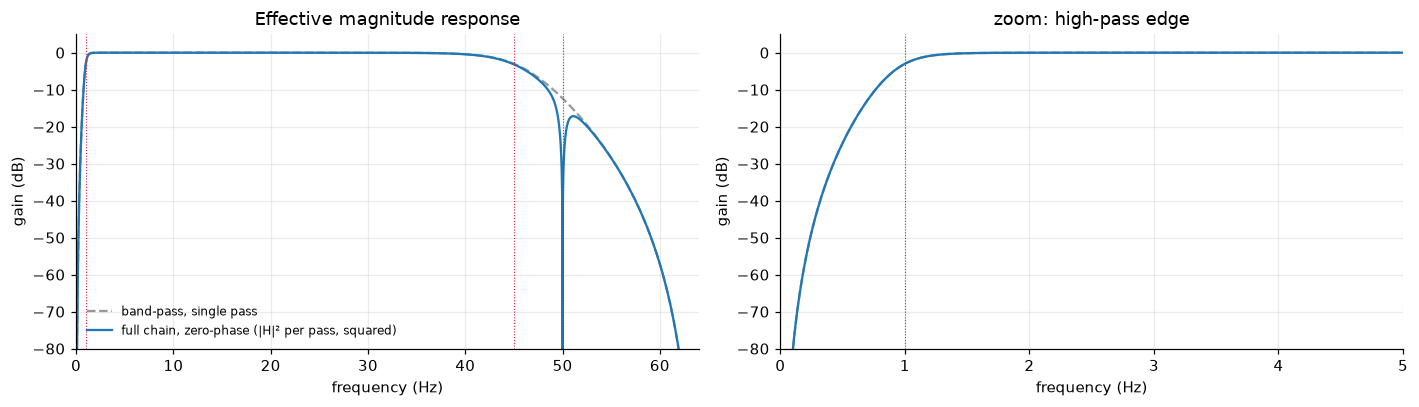

gain at 0.5 Hz -24.4 dB | 1 Hz -3.0 dB | 2 Hz -0.01 dB | 10 Hz -0.00 dB | 45 Hz -3.2 dB | 50 Hz -120.0 dB
50 Hz attenuation from the 45 Hz low-pass alone (zero-phase): -24.7 dB (worst line-noise peak was ~24.5 dB above the local floor)


In [2]:
sos = butter(CFG.filter_order, [CFG.hp_hz, CFG.lp_hz], btype="bandpass", fs=FS, output="sos")
f, h = sosfreqz(sos, worN=8192, fs=FS)
bn, an = iirnotch(CFG.notch_hz, CFG.notch_q, fs=FS)
_, hn = freqz(bn, an, worN=8192, fs=FS)
H2 = np.abs(h) ** 2 * np.abs(hn) ** 2  # forward-backward => squared magnitude
db = lambda v: 10 * np.log10(np.maximum(v, 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, xl in zip(axes, [(0, 64), (0, 5)]):
    ax.plot(f, db(np.abs(h) ** 2), label="band-pass, single pass", color="0.6", ls="--")
    ax.plot(f, db(H2), label="full chain, zero-phase (|H|² per pass, squared)", color="#1f77b4")
    for v in [CFG.hp_hz, CFG.lp_hz, CFG.notch_hz]: ax.axvline(v, color="crimson", lw=0.7, ls=":")
    ax.set_xlim(*xl); ax.set_ylim(-80, 5); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("gain (dB)")
axes[0].set_title("Effective magnitude response"); axes[1].set_title("zoom: high-pass edge"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "filter_response.png", bbox_inches="tight"); plt.show()

g = lambda fr: db(H2[np.argmin(np.abs(f - fr))])
print(f"gain at 0.5 Hz {g(0.5):.1f} dB | 1 Hz {g(1):.1f} dB | 2 Hz {g(2):.2f} dB | 10 Hz {g(10):.2f} dB | 45 Hz {g(45):.1f} dB | 50 Hz {g(50):.1f} dB")
lp_only = db((np.abs(h) ** 2)[np.argmin(np.abs(f - 50))] ** 2)
print(f"50 Hz attenuation from the 45 Hz low-pass alone (zero-phase): {lp_only:.1f} dB (worst line-noise peak was ~24.5 dB above the local floor)")

**Is the notch necessary given the 45 Hz low-pass?** Not strictly. The digital band-pass alone attenuates 50 Hz by ≈ 25 dB (the bilinear
transform compresses frequencies near Nyquist, so the digital roll-off 5 Hz past the cut-off is steeper than the analog prototype suggests),
which brings even the worst line-noise peak (~25 dB above the local floor, sub40_hi) down to roughly the noise floor — see the spectrum below.
The notch adds a large safety margin at 50 Hz for time-domain features (variance, Hjorth parameters, line length), which integrate over all frequencies.
It costs nothing inside the analysis band (its 1.7 Hz bandwidth lies above 45 Hz), and it is applied **to every recording**, not only to the 32
affected ones, so processing is identical across conditions and subjects.

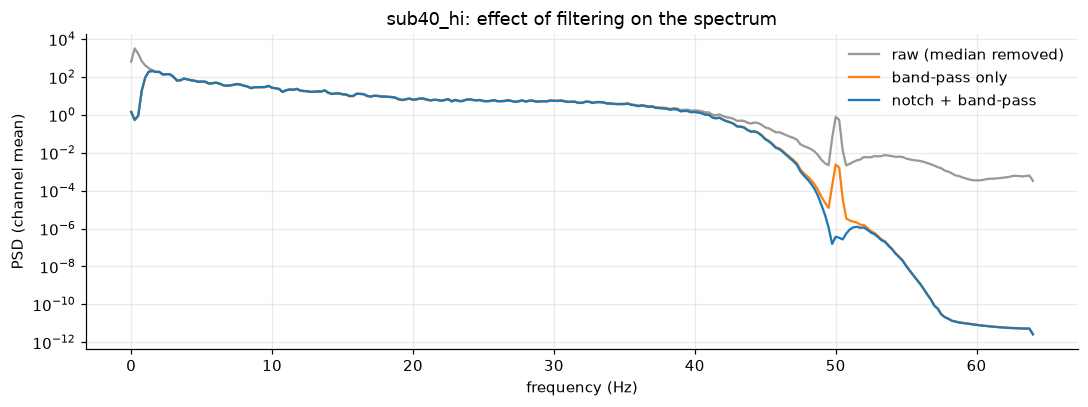

50 Hz PSD: raw 0.779 | band-pass only 0.00239 | with notch 3.68e-07


In [3]:
def psd(x):
    return welch(x, fs=FS, nperseg=4 * FS, axis=0)

ex = (40, "hi")  # worst line-noise recording in Stage 1
raw = recs[ex].data
fr, p_raw = psd(raw - np.median(raw, 0))
_, p_bp = psd(filter_recording(raw, replace(CFG, notch_hz=None)))
_, p_full = psd(filter_recording(raw, CFG))
fig, ax = plt.subplots(figsize=(10, 3.8))
for p, lab, c in [(p_raw, "raw (median removed)", "0.6"), (p_bp, "band-pass only", "#ff7f0e"), (p_full, "notch + band-pass", "#1f77b4")]:
    ax.semilogy(fr, p.mean(1), label=lab, color=c)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD (channel mean)"); ax.set_title(f"sub{ex[0]:02d}_{ex[1]}: effect of filtering on the spectrum")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / "filter_psd_example.png", bbox_inches="tight"); plt.show()
i50 = np.argmin(np.abs(fr - 50))
print(f"50 Hz PSD: raw {p_raw.mean(1)[i50]:.3g} | band-pass only {p_bp.mean(1)[i50]:.3g} | with notch {p_full.mean(1)[i50]:.3g}")

## 2. Before / after filtering in the time domain

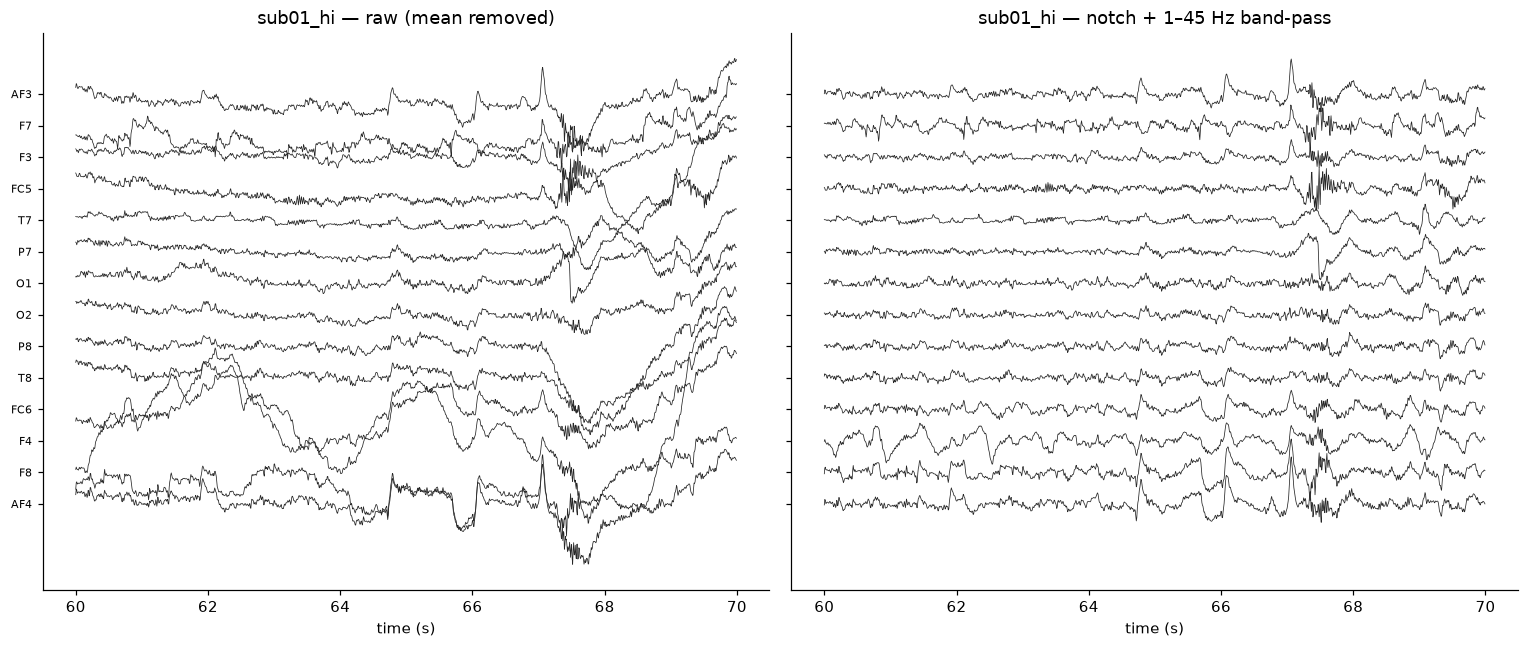

In [4]:
ex = (1, "hi")
raw = recs[ex].data; y = filter_recording(raw, CFG); t = np.arange(len(raw)) / FS
sl = slice(60 * FS, 70 * FS)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, x, title in [(axes[0], raw - raw.mean(0), "raw (mean removed)"), (axes[1], y, "notch + 1–45 Hz band-pass")]:
    for i, ch in enumerate(CHANNELS):
        ax.plot(t[sl], x[sl, i] - i * 120, lw=0.5, color="0.15")
    ax.set_yticks([-i * 120 for i in range(14)], CHANNELS, fontsize=7); ax.set_xlabel("time (s)"); ax.set_title(f"sub01_hi — {title}"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "before_after_time.png", bbox_inches="tight"); plt.show()

## 3. Saturation / dropout mask

Samples at the ADC rails or inside ≥ 0.25 s runs of identical values carry no EEG information. The mask is computed on the **raw**
data (before filtering spreads the discontinuities) and dilated by ±1 s, because the band-pass filter's impulse response "rings" around
step-like discontinuities — the 1 Hz high-pass has the longest time constant, on the order of $1/(2\pi\cdot 1\,\mathrm{Hz})\approx 0.16$ s per pole.

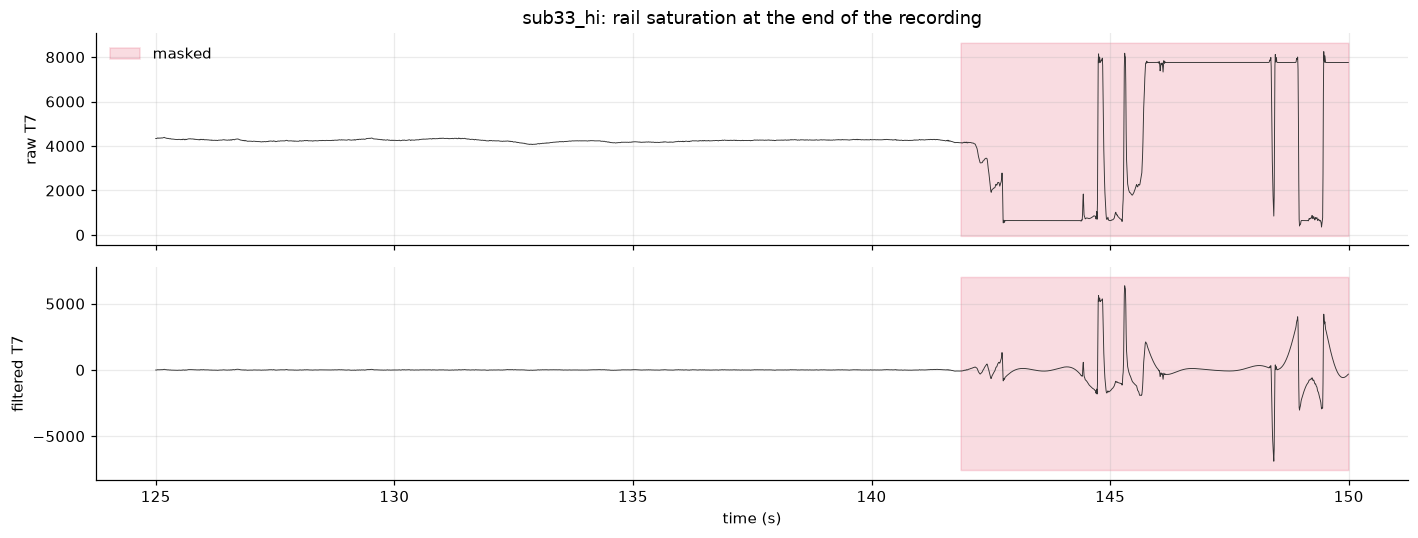

masked samples: overall 0.18%; recordings with any masked sample: 18/96
33  hi    0.040
44  hi    0.029
18  lo    0.022
19  lo    0.017
34  hi    0.014
13  hi    0.014
dtype: float64


In [5]:
ex = (33, "hi")
raw = recs[ex].data; m = bad_sample_mask(raw, CFG); y = filter_recording(raw, CFG); t = np.arange(len(raw)) / FS
ch = CHANNELS.index("T7"); sl = slice(125 * FS, 150 * FS)
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(t[sl], raw[sl, ch], lw=0.6, color="0.2"); axes[0].set_ylabel("raw T7")
axes[1].plot(t[sl], y[sl, ch], lw=0.6, color="0.2"); axes[1].set_ylabel("filtered T7"); axes[1].set_xlabel("time (s)")
for ax in axes:
    ax.fill_between(t[sl], *ax.get_ylim(), where=m[sl, ch], color="crimson", alpha=0.15, label="masked")
axes[0].legend(frameon=False); axes[0].set_title("sub33_hi: rail saturation at the end of the recording")
fig.tight_layout(); fig.savefig(FIG_DIR / "mask_example.png", bbox_inches="tight"); plt.show()
mask_frac = pd.Series({k: bad_sample_mask(r.data, CFG).mean() for k, r in recs.items()})
print(f"masked samples: overall {mask_frac.mean():.2%}; recordings with any masked sample: {(mask_frac > 0).sum()}/96")
print(mask_frac.sort_values(ascending=False).head(6).round(3))

## 4. Run the full pipeline on all recordings

In [6]:
proc = {k: preprocess(r, CFG) for k, r in recs.items()}
W = pd.concat([p.windows for p in proc.values()], ignore_index=True)
bad = pd.DataFrame([dict(subject=s, condition=c, channel=CHANNELS[i]) for (s, c), p in proc.items() for i in np.flatnonzero(p.bad_channels)])
print(f"windows per recording: {len(W) // 96} ({CFG.window_s:.0f} s, step {CFG.step_s:.0f} s); total {len(W)}")
print(f"bad channels: {len(bad)} channel-recordings ({len(bad) / (96 * 14):.1%})")
display(bad.groupby(["subject", "condition"]).channel.apply(list).to_frame().T)

windows per recording: 72 (4 s, step 2 s); total 6912
bad channels: 12 channel-recordings (0.9%)


subject      1      6     13    23     30          33    38           40           41
condition    lo     lo    lo    hi     hi    lo    lo    hi    lo     hi     lo    lo
channel    [T7]  [FC5]  [P8]  [F3]  [FC6]  [F7]  [T7]  [F3]  [F3]  [AF3]  [AF3]  [F3]

## 5. Window rejection threshold

An absolute amplitude threshold is the simplest label-blind criterion and is applied identically to every recording. Conventional
choices for scalp EEG lie between 100 and 200 µV. Below we sweep the threshold and record **which channel** triggers each rejection.

condition,test,rest,rest − test gap
threshold,,,
100,0.579,0.472,-0.107
150,0.341,0.250,-0.091
200,0.245,0.148,-0.096
250,0.194,0.106,-0.087
300,0.167,0.087,-0.080


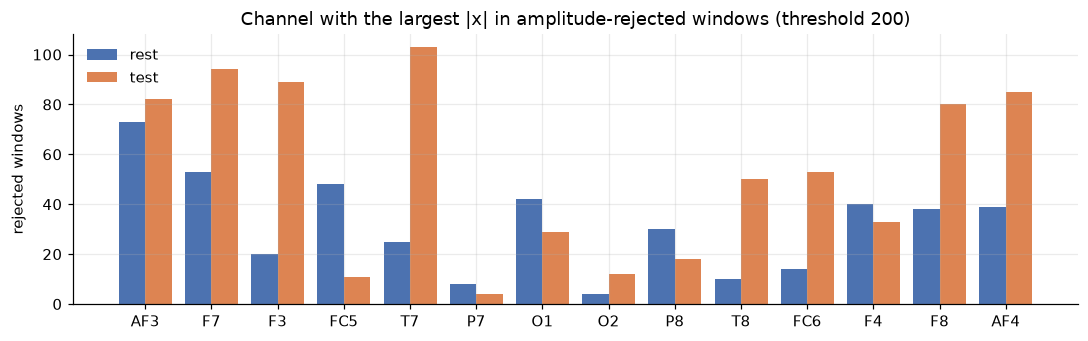

In [7]:
n = int(CFG.window_s * FS)
sweep = []
for th in [100, 150, 200, 250, 300]:
    for (s, c), p in proc.items():
        w = p.windows
        amp = w.max_abs > th
        sweep.append(dict(threshold=th, condition=c, rejected=float((w.reject_mask | amp).mean())))
sweep = pd.DataFrame(sweep).pivot_table(index="threshold", columns="condition", values="rejected").rename(columns=CONDITIONS)
sweep["rest − test gap"] = sweep["rest"] - sweep["test"]
display(sweep.round(3))

drivers = {c: dict.fromkeys(CHANNELS, 0) for c in CONDITIONS}
for (s, c), p in proc.items():
    for st in p.windows.start_sample[p.windows.reject_amplitude & ~p.windows.reject_mask]:
        seg = np.abs(p.x[st:st + n]).copy(); seg[:, p.bad_channels] = 0
        drivers[c][CHANNELS[int(seg.max(0).argmax())]] += 1
drivers = pd.DataFrame(drivers).rename(columns=CONDITIONS)
fig, ax = plt.subplots(figsize=(10, 3.2))
xx = np.arange(14)
ax.bar(xx - 0.2, drivers["rest"], 0.4, color=COND_COLOR["lo"], label="rest"); ax.bar(xx + 0.2, drivers["test"], 0.4, color=COND_COLOR["hi"], label="test")
ax.set_xticks(xx, CHANNELS); ax.set_ylabel("rejected windows"); ax.set_title(f"Channel with the largest |x| in amplitude-rejected windows (threshold {CFG.abs_thresh:.0f})"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "rejection_drivers.png", bbox_inches="tight"); plt.show()

rejection rate by condition:


,reject_mask,reject_amplitude,rejected
condition,,,
test,0.03,0.242,0.245
rest,0.02,0.145,0.148


kept windows per recording: min 6, 10th pct 42, median 60, max 72 (of 72)
recordings with < 20 kept windows: {(27, 'hi'): 6}


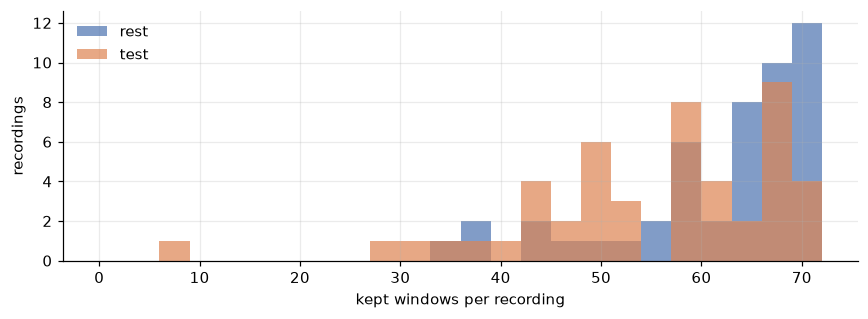

In [8]:
kept = W[~W.rejected].groupby(["subject", "condition"]).size().reindex(pd.MultiIndex.from_tuples(proc.keys(), names=["subject", "condition"]), fill_value=0)
print("rejection rate by condition:"); display(W.groupby("condition")[["reject_mask", "reject_amplitude", "rejected"]].mean().rename(index=CONDITIONS).round(3))
print(f"kept windows per recording: min {kept.min()}, 10th pct {kept.quantile(.1):.0f}, median {kept.median():.0f}, max {kept.max()} (of {len(W) // 96})")
print("recordings with < 20 kept windows:", kept[kept < 20].to_dict())
fig, ax = plt.subplots(figsize=(8, 3))
for c in CONDITIONS:
    ax.hist(kept.xs(c, level="condition"), bins=np.arange(0, 74, 3), alpha=0.7, color=COND_COLOR[c], label=CONDITIONS[c])
ax.set_xlabel("kept windows per recording"); ax.set_ylabel("recordings"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "kept_windows.png", bbox_inches="tight"); plt.show()

**Decision: ±200.** At ±100–150 the rejections are dominated by AF3/AF4/F7/F8 — the electrodes nearest the eyes — i.e. ordinary blinks and saccades,
and 25–58 % of all data would be discarded. ±200 removes gross artifacts (movement, electrode pops, saturation) while keeping ≥ 6 windows in every recording.
Ocular activity that remains is a **known, documented confound**: blink rate and eye movements differ between rest and a visual multitasking test.
We do not attempt ICA-based ocular correction: STEW has no EOG reference channel and automatic component labelling with 14 frontal-heavy
channels is unreliable. Instead, Stage 4 quantifies the confound with ablations (models without the eye-adjacent channels AF3/AF4/F7/F8 and without the delta band).

The rest/test rejection gap persists at every threshold — the test condition is genuinely noisier. Because windows (not recordings) are the model input,
the class balance shifts slightly toward rest; we report balanced metrics and also aggregate to recording level.

## 6. Re-referencing: original vs. common average reference (CAR)

CAR subtracts the instantaneous mean of the good channels: $x_i'(t) = x_i(t) - \frac{1}{|G|}\sum_{j\in G} x_j(t)$.
It cancels any signal common to all electrodes (e.g. reference-electrode disturbances, as seen in sub44_hi) but approximates a
zero-potential reference only when electrodes cover the scalp densely and uniformly. The EPOC's 14 electrodes are concentrated frontally
(8 of 14 are AF/F/FC), so the average is dominated by frontal — including ocular — activity, which CAR would *inject into every posterior channel*.

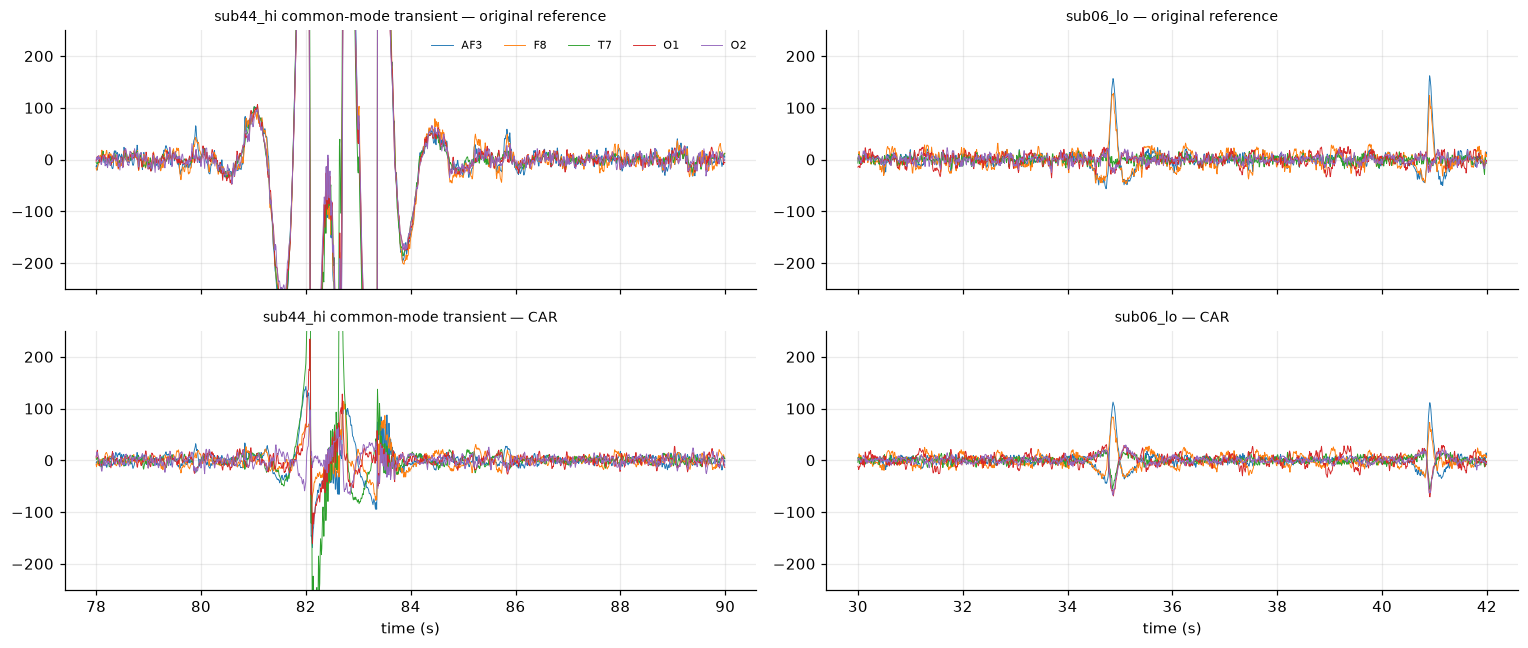

,original,CAR
condition,,
test,0.245,0.212
rest,0.148,0.128


In [9]:
ex = (44, "hi"); p0 = proc[ex]; xc = rereference(p0.x.astype(float), ~p0.bad_channels, "average")
t = np.arange(len(p0.x)) / FS; sl = slice(78 * FS, 90 * FS)
blk = (6, "lo"); pb = proc[blk]; xb = rereference(pb.x.astype(float), ~pb.bad_channels, "average")
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex="col")
for col, (pp, xx_, title) in enumerate([(p0, xc, "sub44_hi common-mode transient"), (pb, xb, "sub06_lo")]):
    for row, (x, lab) in enumerate([(pp.x, "original reference"), (xx_, "CAR")]):
        ax = axes[row, col]
        s_ = sl if col == 0 else slice(30 * FS, 42 * FS)
        for ch in ["AF3", "F8", "T7", "O1", "O2"]:
            ax.plot(t[s_], x[s_, CHANNELS.index(ch)], lw=0.6, label=ch)
        ax.set_title(f"{title} — {lab}", fontsize=9); ax.set_ylim(-250, 250)
axes[0, 0].legend(frameon=False, fontsize=7, ncol=5); axes[1, 0].set_xlabel("time (s)"); axes[1, 1].set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(FIG_DIR / "reference_comparison.png", bbox_inches="tight"); plt.show()

proc_car = {k: preprocess(r, replace(CFG, reference="average")) for k, r in recs.items()}
Wc = pd.concat([p.windows for p in proc_car.values()])
cmp = pd.DataFrame({"original": W.groupby("condition").rejected.mean(), "CAR": Wc.groupby("condition").rejected.mean()}).rename(index=CONDITIONS)
display(cmp.round(3))

**Decision: keep the original (headset) reference** for the main pipeline. CAR removes rare common-mode transients (which amplitude rejection
already catches) at the price of spreading frontal ocular activity to posterior channels, worsening the very confound we want to contain. CAR stays
available as `PreprocessConfig(reference="average")`.

## 7. Normalisation

No amplitude normalisation is applied at this stage, deliberately:
- Per-window z-scoring would erase absolute power — precisely the quantity that band-power features measure.
- Feature standardisation $z = (x-\mu_{train})/\sigma_{train}$ is a *learned* transform; it lives inside the scikit-learn pipeline so that
  $\mu,\sigma$ are estimated on training subjects only within each CV fold.
- Subject-level baseline normalisation is a personalisation question and is studied separately in Stage 6.
- Log transforms of power (Stage 3) handle the strongly right-skewed, multiplicative nature of EEG power across subjects.

## 8. Save outputs

The filtered signals are cheap to recompute (≈ 5 s for all 96 recordings) and deterministic, so only the window table (metadata and
reject flags) and the bad-channel list are stored; Stage 3 re-runs `preprocess` in memory.

In [10]:
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
W.to_csv(PROC / "windows.csv", index=False)
bad.to_csv(PROC / "bad_channels.csv", index=False)
summary = {
    "config": asdict(CFG),
    "n_windows_total": int(len(W)), "windows_per_recording": int(len(W) // 96),
    "rejection_rate": W.groupby("condition").rejected.mean().round(4).to_dict(),
    "rejection_reason_rate": {"mask": float(W.reject_mask.mean()), "amplitude": float(W.reject_amplitude.mean())},
    "kept_windows": {"total": int((~W.rejected).sum()), "by_condition": W[~W.rejected].condition.value_counts().to_dict(),
                     "min_per_recording": int(kept.min()), "median_per_recording": float(kept.median())},
    "bad_channels": bad.to_dict(orient="records"),
    "threshold_sweep": sweep.round(4).reset_index().to_dict(orient="records"),
    "car_rejection_rate": Wc.groupby("condition").rejected.mean().round(4).to_dict(),
}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved:", (PROC / "windows.csv").relative_to(ROOT), (PROC / "bad_channels.csv").relative_to(ROOT), (OUT / "summary.json").relative_to(ROOT))

saved: data/processed/windows.csv data/processed/bad_channels.csv results/02_preprocessing/summary.json


## 9. Findings

- **Filtering.** The zero-phase chain has −3 dB at 1 Hz and 45 Hz, < 0.01 dB ripple from 2 to 40 Hz, and −24 dB at 0.5 Hz. The band-pass alone
  already suppresses 50 Hz by ≈ 25 dB; the uniform notch removes the residual (50 Hz PSD of the worst recording: 0.78 → 2.4×10⁻³ → 3.7×10⁻⁷).
- **Masking.** Only 0.18 % of samples are saturated or flat, concentrated in 18 recordings (worst: sub33_hi, 4 %).
- **Bad channels.** 12 of 1344 channel-recordings (0.9 %) exceed 4× their recording's median robust SD (e.g. sub01_lo T7, sub40 AF3 in both
  conditions, sub38 F3 in both). They are set to NaN and handled by imputation inside the model pipeline (fit on training folds only).
- **Window rejection (±200).** 6912 windows of 4 s (72 per recording). Rejected: 24.5 % of test windows vs 14.8 % of rest windows. Kept: 5 554 windows (2 943 rest, 2 611 test),
  median 60 per recording, minimum 6 (sub27_hi). The test condition is noisier at every threshold (gap 8–11 points), driven by frontal/temporal
  channels (AF3, F7, F3, T7, F8, AF4, T8) — consistent with more eye movement and jaw/temporal muscle activity during the task.
- **Reference.** CAR lowers rejection by ~2–3 points but redistributes frontal transients into posterior channels as inverted copies; the original
  reference is kept. Several transients (e.g. sub06_lo) appear with near-identical shape on frontal *and* occipital channels, suggesting reference-side
  disturbances — another reason residual artifact must be treated as a possible confound.

**Carried forward to Stage 3–5:** extract features from the 5 554 kept windows, keep subject as the grouping variable, use balanced metrics,
and run ablations without eye-adjacent channels / without delta to estimate how much classification relies on ocular or muscle activity.